# Notebook 07c — A stricter court matcher, events, and features courts refused to call stock

Added November 2026. Notebook 07b matched three quarters of the court-named features by reducing the court's phrase to its last noun, and the last noun of a phrase is usually a common word. Its head-noun null showed that this step alone produces the high prevalence of those matches. This notebook rebuilds the matching so that it prefers the longest phrase it can find and declines to match when it finds nothing sound, and it repeats the two baselines of 07b on the cleaner matches. It then scores a first, unaudited list of features that courts refused to call stock.

**The matcher, in order. Each step is a rule about wording; none looks at any score, and none uses a language model or an embedding.**

1. **Exact.** The court's phrase is itself in the pipeline's vocabulary.
2. **Phrase.** The longest run of two or more consecutive words from the court's phrase that is in the vocabulary ("significant consequences of time travel" gives "time travel"). The last word is tried in the singular first.
3. **Event.** The phrase is parsed as in Notebook 13 and an event of that notebook is found in it ("riding a dark horse" gives "ride horse").
4. **Head.** The grammatical head of the phrase, from the parser, when it is a noun ("small miseries of domestic life" gives "misery", where 07b's last-noun rule gave "life").
5. **Decline.** Otherwise the phrase is left unmatched.

Steps 1 to 3 are the **strict** set: the match is the court's own wording or a multi-word part of it. Step 4 still reduces a phrase to one word and is reported separately.

**Read-only on Mira's data.** Nothing in `07_court_cases/` is written. Outputs go to `v4_rebuild/07c_court_matcher_v2/`.

In [1]:
import os, re, sys, json, shutil, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, mannwhitneyu

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path('/Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/'
         'My Drive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path.cwd() / 'v4_rebuild',
    Path.cwd().parent / 'v4_rebuild',
]
V4 = next((c for c in _CANDS if c.exists()), None)
assert V4 is not None, 'Could not locate v4_rebuild; set V4 manually.'
OUT = V4 / '07c_court_matcher_v2'
OUT.mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local, **kw)

import spacy
try:
    nlp = spacy.load('en_core_web_sm', disable=['ner'])
except OSError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'], check=True)
    nlp = spacy.load('en_core_web_sm', disable=['ner'])

MATCH_WINDOW, MIN_CONTROLS = 0.02, 5
DIMS = ['prevalence', 'distinctiveness']
report = []
def out(s=''):
    print(s); report.append(s)
print('V4 =', V4); print('OUT =', OUT)

V4 = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild
OUT = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/07c_court_matcher_v2


## Load the court features, the feature scores and the event scores

In [2]:
judicial = read_parquet(V4 / '07_court_cases' / 'judicial_elements_CURATED.parquet')
stk = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet')
ev  = read_parquet(V4 / '13_event_elements' / 'event_scores.parquet')
CANON = sorted(stk['genre'].unique())

def norm(s):
    if s is None:
        return ''
    t = re.sub(r'\s+', ' ', str(s).lower().strip())
    return '' if t in {'none', 'nan', 'null'} else t

# The same in-scope rows as Notebook 07b.
J = judicial[(judicial['scope_tag'] == 'in_scope') & (judicial['kind'] != 'no_extraction')].copy()
J['phrase'] = J['element'].map(norm)
J['gen'] = J['relevant_genre']
J = J[J['gen'].isin(CANON) & (J['phrase'].str.len() > 0)].reset_index(drop=True)
J['case'] = J['cluster_id'].where(J['cluster_id'].notna(), J['caseName']).astype(str)
J['label'] = 'held_stock'
assert len(J) == 416, len(J)

# Feature percentiles within (genre, type), on the best-type row, exactly as in 07b.
stk['p_prevalence'] = stk.groupby(['genre', 'element_type'])['rel_freq_in_genre'].rank(pct=True)
stk['p_distinctiveness'] = stk.groupby(['genre', 'element_type'])['posterior_smoothed'].rank(pct=True)
best = stk.sort_values('ensemble').groupby(['element', 'genre']).tail(1)
EL = best.set_index(['element', 'genre'])[['p_prevalence', 'p_distinctiveness', 'element_type', 'is_narrative_element']].sort_index()
VOCAB = set(stk['element'].unique())
NARR = stk.drop_duplicates('element').set_index('element')['is_narrative_element']

# Events: one row per (event, genre); percentiles are within genre and event kind (Notebook 13).
ev = ev.sort_values('film_count').drop_duplicates(['event', 'genre'], keep='last')
EV = ev.set_index(['event', 'genre'])[['p_prevalence', 'p_distinctiveness', 'event_type']].sort_index()
EVOCAB = set(ev['event'].unique())
print(f'{len(J)} court features; {len(VOCAB):,} vocabulary strings; {len(EVOCAB):,} events')

416 court features; 22,677 vocabulary strings; 18,715 events


## The matcher

In [3]:
STOP_HEADS = {'the', 'a', 'an', 'of', 'scene', 'scenes', 'element', 'elements', 'thing', 'things',
              'setting', 'settings', 'character', 'characters', 'story', 'plot', 'theme', 'themes',
              'use', 'kind', 'type', 'format', 'off', 'out', 'over', 'up', 'down', 'in', 'on'}
SKIP_VERBS = {'be', 'have', 'do'}
EVENT_ORDER = {'verb_prep_object': 0, 'verb_object': 1, 'subject_verb': 2}

def singular_first(w):
    c = []
    if w.endswith('ies') and len(w) > 4: c.append(w[:-3] + 'y')
    if w.endswith('s') and not w.endswith('ss') and len(w) > 3: c.append(w[:-1])
    if w.endswith('es') and len(w) > 4: c.append(w[:-2])
    c.append(w)
    return list(dict.fromkeys(c))

def longest_phrase(phrase):
    # Longest run of 2+ consecutive words in the vocabulary; among equal lengths, the one nearest the end.
    toks = re.findall(r"[a-z']+", phrase)
    for n in range(min(len(toks), 5), 1, -1):
        for i in range(len(toks) - n, -1, -1):
            g = toks[i:i + n]
            for last in singular_first(g[-1]):
                cand = ' '.join(g[:-1] + [last])
                if cand in VOCAB:
                    return cand
    return None

def events_of(doc):
    # Identical rules to Notebook 13, returned in order of appearance.
    found = []
    for tok in doc:
        if tok.pos_ != 'VERB':
            continue
        v = tok.lemma_.lower()
        if v in SKIP_VERBS or not v.isalpha():
            continue
        prt = [c.lemma_.lower() for c in tok.children if c.dep_ == 'prt']
        if prt:
            v = v + ' ' + prt[0]
        def nouns(head):
            return [n.lemma_.lower() for n in [head] + list(head.conjuncts) if n.pos_ == 'NOUN' and n.lemma_.isalpha() and len(n.lemma_) > 1]
        for c in tok.children:
            if c.dep_ in ('dobj', 'nsubjpass'):
                found += [(f'{v} {n}', 'verb_object') for n in nouns(c)]
            elif c.dep_ == 'nsubj':
                found += [(f'{n} {v}', 'subject_verb') for n in nouns(c)]
            elif c.dep_ == 'prep':
                for gc in c.children:
                    if gc.dep_ == 'pobj':
                        found += [(f'{v} {c.lemma_.lower()} {n}', 'verb_prep_object') for n in nouns(gc)]
            elif c.dep_ == 'agent':
                for gc in c.children:
                    if gc.dep_ == 'pobj':
                        found += [(f'{n} {v}', 'subject_verb') for n in nouns(gc)]
    return found

def match_all(phrases):
    res = []
    for p, doc in zip(phrases, nlp.pipe(phrases)):
        if p in VOCAB:
            res.append((p, 'exact', 'element')); continue
        g = longest_phrase(p)
        if g:
            res.append((g, 'phrase', 'element')); continue
        evs = [e for e in events_of(doc) if e[0] in EVOCAB]
        if evs:
            evs.sort(key=lambda e: EVENT_ORDER[e[1]])
            res.append((evs[0][0], 'event', 'event')); continue
        root = [t for t in doc if t.dep_ == 'ROOT']
        hit = None
        if root and root[0].pos_ == 'NOUN':
            for c in singular_first(root[0].text.lower()):
                if c in VOCAB and c not in STOP_HEADS:
                    hit = c; break
        res.append((hit, 'head', 'element') if hit else (None, 'declined', None))
    return pd.DataFrame(res, columns=['match', 'tier', 'unit'])

J = pd.concat([J, match_all(J['phrase'].tolist())], axis=1)
old = read_parquet(V4 / '07b_court_validation' / 'matched_judicial_elements.parquet')[['element', 'gen', 'match_element', 'match_method']].drop_duplicates(['element', 'gen'])
J = J.merge(old.rename(columns={'match_element': 'match_07b', 'match_method': 'method_07b'}), on=['element', 'gen'], how='left')
cov = J['tier'].value_counts().reindex(['exact', 'phrase', 'event', 'head', 'declined']).fillna(0).astype(int)
out('NOTEBOOK 07c — STRICTER COURT MATCHER, EVENTS, REJECTED ELEMENTS')
out(f'{len(J)} in-scope court features')
out(''); out('COVERAGE BY TIER'); out(cov.to_string())
out(f"strict set (exact + phrase + event): {int(cov[['exact', 'phrase', 'event']].sum())}   (07b had {int((J['method_07b'] == 'exact').sum())} exact matches)")
out(''); out('new tier (rows) against the 07b method (columns)')
out(pd.crosstab(J['tier'], J['method_07b'].fillna('unmatched')).to_string())
J[['cluster_id', 'caseName', 'gen', 'element', 'phrase', 'match', 'tier', 'unit', 'match_07b', 'method_07b']].to_csv(OUT / 'match_review_sheet_v2.csv', index=False)
J[J['tier'].isin(['phrase', 'event'])][['phrase', 'match', 'tier', 'match_07b']].sample(20, random_state=1)

NOTEBOOK 07c — STRICTER COURT MATCHER, EVENTS, REJECTED ELEMENTS
416 in-scope court features

COVERAGE BY TIER
tier
exact        66
phrase       63
event        15
head        199
declined     73
strict set (exact + phrase + event): 144   (07b had 66 exact matches)

new tier (rows) against the 07b method (columns)
method_07b  exact  head_noun  semantic  unmatched
tier                                             
declined        0         50        17          6
event           0         14         1          0
exact          66          0         0          0
head            0        197         2          0
phrase          0         59         4          0


,phrase,match,tier,match_07b
386,jesus character engaging in un-jesuslike behavior,engage in behavior,event,behavior
414,love triangles,love triangle,phrase,triangle
239,youth committing a crime,commit crime,event,crime
180,female character held captive,female character,phrase,captive
371,military commander addressing crowd,military commander,phrase,crowd
405,warning signs of impending time travel,time travel,phrase,travel
362,reunion evoking feeling of time machine,time machine,phrase,machine
324,girl with psychic abilities,psychic ability,phrase,ability
300,half-vampire half-human character,half vampire,phrase,half vampire
204,victim of police shakedown expressing disdain ...,corrupt cop,phrase,cop


## Score the matches and repeat the two baselines of 07b

**Rank of the court's genre.** For each matched feature or event, the genres in which it appears are ordered by its within-genre percentile, and the position of the court's genre is recorded from 0 to 1. Chance is 0.5.

**Matched controls.** Each matched feature or event is compared with others of the same genre and kind that match it on one dimension (percentile within 0.02), and the difference on the other dimension is taken in percentile points. Court-named items are excluded from the control pools. Features are compared with story features of the same grammatical type, events with events of the same kind.

Each case contributes the mean (rank) or median (controls) of its items, and a Wilcoxon signed-rank test over cases compares the case values with chance. Feature matches are restricted to story features, as in 07b.

In [4]:
def midrank(own, others):
    others = np.asarray(others, dtype=float)
    return float(((others < own).sum() + 0.5 * (others == own).sum()) / len(others))

def case_test(s, mu=0.0):
    d = s - mu
    nz = d[d != 0]
    return {'n_cases': int(len(s)), 'median_case': float(s.median()), 'cases_above': int((d > 0).sum()),
            'p': float(wilcoxon(nz).pvalue) if len(nz) >= 6 else float('nan')}

def build_pools(court_keys):
    b = best[['element', 'genre', 'element_type', 'p_prevalence', 'p_distinctiveness', 'is_narrative_element']]
    b = b[b['is_narrative_element'] & ~pd.Series(list(zip(b['element'], b['genre'])), index=b.index).isin(court_keys['element'])]
    e = ev[['event', 'genre', 'event_type', 'p_prevalence', 'p_distinctiveness']]
    e = e[~pd.Series(list(zip(e['event'], e['genre'])), index=e.index).isin(court_keys['event'])]
    return ({k: d for k, d in b.groupby(['genre', 'element_type'])}, {k: d for k, d in e.groupby(['genre', 'event_type'])})

def score(df):
    # One row per matched item that has a score in the court's genre.
    recs = []
    for r in df.itertuples(index=False):
        if r.unit == 'element':
            if (r.match, r.gen) not in EL.index or not bool(NARR.get(r.match, False)):
                continue
            allg = EL.loc[r.match]; kind = allg.loc[r.gen, 'element_type']
        elif r.unit == 'event':
            if (r.match, r.gen) not in EV.index:
                continue
            allg = EV.loc[r.match]; kind = allg.loc[r.gen, 'event_type']
        else:
            continue
        own, oth = allg.loc[r.gen], allg[allg.index != r.gen]
        rec = {'case': r.case, 'caseName': r.caseName, 'gen': r.gen, 'phrase': r.phrase, 'match': r.match, 'tier': r.tier,
               'unit': r.unit, 'kind': kind, 'label': r.label, 'n_genres': int(len(allg))}
        for n in DIMS:
            rec[f'p_{n}'] = float(own[f'p_{n}'])
            rec[f'rank_{n}'] = midrank(own[f'p_{n}'], oth[f'p_{n}'].values) if len(oth) else np.nan
        recs.append(rec)
    return pd.DataFrame(recs)

def add_controls(S, pools_el, pools_ev):
    S = S.copy()
    for match_on, compare in [('prevalence', 'distinctiveness'), ('distinctiveness', 'prevalence')]:
        vals = []
        for r in S.itertuples(index=False):
            pool = (pools_el if r.unit == 'element' else pools_ev).get((r.gen, r.kind))
            own_m, own_c = getattr(r, f'p_{match_on}'), getattr(r, f'p_{compare}')
            if pool is None:
                vals.append(np.nan); continue
            c = pool[(pool[f'p_{match_on}'] - own_m).abs() <= MATCH_WINDOW]
            vals.append(own_c - c[f'p_{compare}'].mean() if len(c) >= MIN_CONTROLS else np.nan)
        S[f'{compare}_vs_controls'] = vals
    return S

S = score(J)
court_keys = {'element': set(zip(S[S['unit'] == 'element']['match'], S[S['unit'] == 'element']['gen'])),
              'event':   set(zip(S[S['unit'] == 'event']['match'],   S[S['unit'] == 'event']['gen']))}
POOL_EL, POOL_EV = build_pools(court_keys)
S = add_controls(S, POOL_EL, POOL_EV)
S.to_parquet(OUT / 'scored_matches_v2.parquet', index=False)

SETS = {'strict (exact + phrase + event)': ['exact', 'phrase', 'event'], 'exact': ['exact'], 'phrase': ['phrase'],
        'event': ['event'], 'head': ['head'], 'all tiers': ['exact', 'phrase', 'event', 'head']}
rows, case_long = [], []
for name, tiers in SETS.items():
    d = S[S['tier'].isin(tiers)]
    base = {'set': name, 'n_items': int(len(d)), 'median_p_prevalence': float(d['p_prevalence'].median()),
            'median_p_distinctiveness': float(d['p_distinctiveness'].median())}
    for n in DIMS:
        cm = d.dropna(subset=[f'rank_{n}']).groupby('case')[f'rank_{n}'].mean()
        rows.append({**base, 'baseline': 'court_genre_rank', 'measure': n, **case_test(cm, 0.5)})
        case_long.append(pd.DataFrame({'set': name, 'baseline': 'court_genre_rank', 'measure': n, 'case': cm.index, 'value': cm.values}))
    for col, lab in [('distinctiveness_vs_controls', 'distinctiveness_given_prevalence'), ('prevalence_vs_controls', 'prevalence_given_distinctiveness')]:
        cm = d.dropna(subset=[col]).groupby('case')[col].median()
        rows.append({**base, 'baseline': 'matched_controls', 'measure': lab, **case_test(cm, 0.0)})
        case_long.append(pd.DataFrame({'set': name, 'baseline': 'matched_controls', 'measure': lab, 'case': cm.index, 'value': cm.values}))
res = pd.DataFrame(rows)
res.to_parquet(OUT / 'baselines_v2.parquet', index=False)
pd.concat(case_long, ignore_index=True).to_parquet(OUT / 'baselines_v2_by_case.parquet', index=False)
out(''); out('SCORED ITEMS AND BASELINES BY MATCH TIER  (features: narrative only)')
for name in SETS:
    d = res[res['set'] == name]
    r0 = d.iloc[0]
    out(f"  {name}: {int(r0['n_items'])} items; median percentile in the court genre: prevalence {r0['median_p_prevalence']:.3f}, distinctiveness {r0['median_p_distinctiveness']:.3f}")
    for _, r in d.iterrows():
        if r['baseline'] == 'court_genre_rank':
            out(f"      rank of court genre, {r['measure']:<16} case median {r['median_case']:.3f}  {int(r['cases_above'])}/{int(r['n_cases'])} cases > 0.5  p={r['p']:.1e}")
        else:
            out(f"      {r['measure']:<34} case median {r['median_case']:+.3f}  {int(r['cases_above'])}/{int(r['n_cases'])} cases > 0  p={r['p']:.1e}")


SCORED ITEMS AND BASELINES BY MATCH TIER  (features: narrative only)
  strict (exact + phrase + event): 133 items; median percentile in the court genre: prevalence 0.880, distinctiveness 0.804
      rank of court genre, prevalence       case median 0.766  39/46 cases > 0.5  p=2.3e-08
      rank of court genre, distinctiveness  case median 0.760  40/46 cases > 0.5  p=2.1e-06
      distinctiveness_given_prevalence   case median +0.117  34/46 cases > 0  p=1.6e-02
      prevalence_given_distinctiveness   case median +0.141  37/46 cases > 0  p=2.9e-06
  exact: 59 items; median percentile in the court genre: prevalence 0.873, distinctiveness 0.763
      rank of court genre, prevalence       case median 0.790  21/26 cases > 0.5  p=6.4e-05
      rank of court genre, distinctiveness  case median 0.790  19/26 cases > 0.5  p=9.1e-04
      distinctiveness_given_prevalence   case median +0.156  18/26 cases > 0  p=8.4e-02
      prevalence_given_distinctiveness   case median +0.143  21/26 cases > 0 

## Figures

The figures below are ordinary matplotlib plots with matplotlib's default look. Each is shown here and saved as a PNG in this notebook's `figures/` folder. The talk's slides use those PNG files as they are.

In [5]:
import matplotlib.pyplot as plt
plt.rcdefaults()                                   # matplotlib's own defaults: white background, boxed axes, DejaVu Sans
plt.rcParams.update({'font.size': 10})            # figures are drawn at the size they have on the slide
BLUE, RED = 'tab:blue', 'tab:red'                  # prevalence is blue, distinctiveness is red, in every figure
FIGDIR = OUT / 'figures'
FIGDIR.mkdir(exist_ok=True)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', dpi=200, facecolor='white', bbox_inches='tight')
    plt.show()

### Which dimension, on all matches and on the court's own wording

Each dot is one case. Red: the court-named features' distinctiveness minus that of equally common controls. Blue: their prevalence minus that of equally characteristic controls. The boxes show the median and the middle half of the cases.

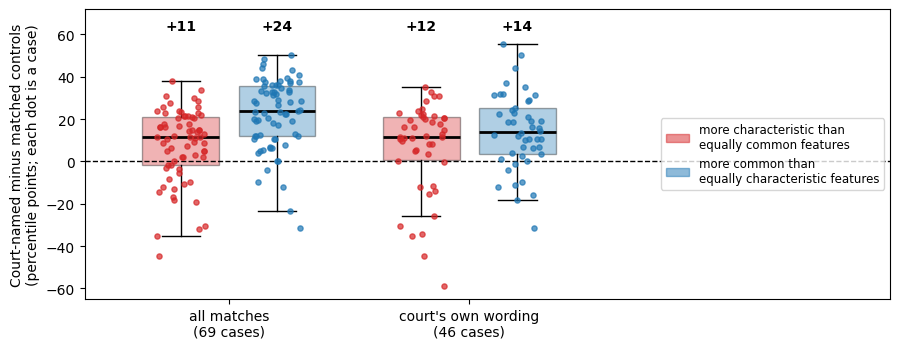

In [6]:
CL = pd.concat(case_long, ignore_index=True)
CL = CL[CL['baseline'] == 'matched_controls']
STRICT = 'strict (exact + phrase + event)'
def vals_of(st, measure):
    return 100 * CL[(CL['set'] == st) & (CL['measure'] == measure)]['value'].values
fig, ax = plt.subplots(figsize=(9.1, 3.6))
jit = np.random.default_rng(20260219)
groups = [('all tiers', 'all matches'), (STRICT, "court's own wording")]
for gi, (st, _) in enumerate(groups):
    for off, col, meas in [(-0.2, RED, 'distinctiveness_given_prevalence'), (0.2, BLUE, 'prevalence_given_distinctiveness')]:
        v = vals_of(st, meas)
        ax.boxplot(v, positions=[gi + off], widths=0.32, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=col, alpha=0.35), medianprops=dict(color='black', lw=2))
        ax.scatter(gi + off + jit.uniform(-0.1, 0.1, len(v)), v, s=14, color=col, alpha=0.7, zorder=3)
        ax.text(gi + off, 62, f'{np.median(v):+.0f}', ha='center', fontweight='bold')
ax.axhline(0, color='black', ls='--', lw=1)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"{lbl}\n({len(vals_of(st, 'distinctiveness_given_prevalence'))} cases)" for st, lbl in groups])
ax.set_ylim(-65, 72); ax.set_xlim(-0.6, 2.75); ax.set_ylabel('Court-named minus matched controls\n(percentile points; each dot is a case)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=RED, alpha=0.5, label='more characteristic than\nequally common features'),
                   Patch(color=BLUE, alpha=0.5, label='more common than\nequally characteristic features')], loc='center right', fontsize=8.5)
save(fig, 'court_matched')

### How the court phrases were matched

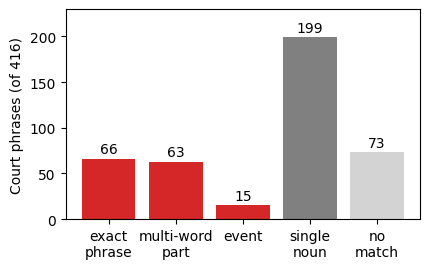

In [7]:
tier_lab = {'exact': 'exact\nphrase', 'phrase': 'multi-word\npart', 'event': 'event', 'head': 'single\nnoun', 'declined': 'no\nmatch'}
order_t = ['exact', 'phrase', 'event', 'head', 'declined']
fig, ax = plt.subplots(figsize=(4.4, 2.8))
ax.bar([tier_lab[t] for t in order_t], [cov[t] for t in order_t], color=[RED, RED, RED, 'gray', 'lightgray'])
for i, t in enumerate(order_t):
    ax.text(i, cov[t] + 3, str(int(cov[t])), ha='center', va='bottom')
ax.set_ylim(0, 230); ax.set_ylabel(f'Court phrases (of {len(J)})')
save(fig, 'matcher_tiers')

## Features courts refused to call stock (first pass, not yet audited)

The curated court data hold only features that courts held to be scènes à faire. A test that separates stock from non-stock needs the other side too. As a first pass, the scènes à faire passages of the in-scope opinions were read for features that the court expressly refused to treat as scènes à faire or expressly treated as protectable, each with a verbatim quotation. Every quotation was checked by exact match against the passage text, and rows that failed were dropped. **The list was extracted by a language model and has not been checked by a person**, so everything in this section is preliminary. The list is `rejected_elements_DRAFT.csv` in this notebook's output folder; if the file is absent this section is skipped.

The rejected features go through the same matcher and are scored in the genre of their case. Two cautions apply. Courts usually protect specific combinations and sequences, which have no single score here, so most rejected rows are long phrases that the matcher declines. And a court refusing to call a feature stock in one case is weaker evidence than a court calling it stock.

In [8]:
PATH_NEG = OUT / 'rejected_elements_DRAFT.csv'
if not PATH_NEG.exists():
    print('rejected_elements_DRAFT.csv not found; skipping this section.')
    NEG = None
else:
    NEG = pd.read_csv(PATH_NEG)
    NEG['phrase'] = NEG['element'].map(norm)
    NEG['gen'] = NEG['genre']
    NEG = NEG[NEG['gen'].isin(CANON) & (NEG['phrase'].str.len() > 0)].reset_index(drop=True)
    NEG['case'] = NEG['cluster_id'].astype(str)
    NEG['label'] = 'refused'
    NEG = pd.concat([NEG, match_all(NEG['phrase'].tolist())], axis=1)
    SN = score(NEG)
    out(''); out('ELEMENTS COURTS REFUSED TO CALL STOCK (first pass; extracted by a language model, quotations verified, not human-audited)')
    out(f"{len(NEG)} rows in {NEG['case'].nunique()} cases; by kind: {NEG['kind'].value_counts().to_dict()}; by holding: {NEG['holding_type'].value_counts().to_dict()}")
    out('matcher tiers: ' + str(NEG['tier'].value_counts().to_dict()))
    out(f'scored in the court genre (story features and events): {len(SN)}')
    SN.to_parquet(OUT / 'scored_rejected_v2.parquet', index=False)
    comp = []
    for name, tiers in [('strict', ['exact', 'phrase', 'event']), ('all tiers', ['exact', 'phrase', 'event', 'head'])]:
        a, b = S[S['tier'].isin(tiers)], SN[SN['tier'].isin(tiers)]
        for n in DIMS + ['rank_prevalence', 'rank_distinctiveness']:
            col = n if n.startswith('rank_') else f'p_{n}'
            x, y = a[col].dropna(), b[col].dropna()
            if len(y) >= 5:
                u = mannwhitneyu(x, y, alternative='two-sided')
                comp.append({'set': name, 'measure': col, 'n_held_stock': len(x), 'n_refused': len(y), 'median_held_stock': float(x.median()),
                             'median_refused': float(y.median()), 'auc_held_stock_higher': float(u.statistic / (len(x) * len(y))), 'p': float(u.pvalue)})
    comp = pd.DataFrame(comp)
    comp.to_parquet(OUT / 'held_vs_refused.parquet', index=False)
    out(comp.round(3).to_string(index=False) if len(comp) else 'too few scored refused features to compare')
    if len(SN):
        out(''); out('scored refused features:')
        out(SN[['caseName', 'gen', 'phrase', 'match', 'tier', 'p_prevalence', 'p_distinctiveness']].round(2).to_string(index=False))


ELEMENTS COURTS REFUSED TO CALL STOCK (first pass; extracted by a language model, quotations verified, not human-audited)
23 rows in 14 cases; by kind: {'single': 13, 'combination': 10}; by holding: {'rejected_as_scenes_a_faire': 13, 'held_protectable': 10}
matcher tiers: {'phrase': 11, 'declined': 6, 'head': 4, 'event': 2}
scored in the court genre (story features and events): 13
      set              measure  n_held_stock  n_refused  median_held_stock  median_refused  auc_held_stock_higher     p
   strict         p_prevalence           133         13              0.880           0.723                  0.626 0.136
   strict    p_distinctiveness           133         13              0.804           0.781                  0.561 0.473
   strict      rank_prevalence           133         13              0.818           0.778                  0.548 0.564
   strict rank_distinctiveness           133         13              0.857           0.778                  0.573 0.383
all tiers      

## The hand check of the phrase and event matches

On November 18, 2026 David Kamper went through the 78 phrase and event matches by hand and marked, for each, whether the matched story feature keeps the meaning of the court's phrase (`same_meaning_Y_N` in `match_check_78_reviewed.csv`). A second pass by a language model sits in the column beside it (`reviewed_Y_N`). **All 78 matches are kept in the results above.** Each phrase match is a run of two or more of the court's own words, and each event match is an event the parser found in the court's phrase; the check asked the stricter question of whether the match carries the meaning of the whole phrase. A match marked N keeps part of it: "female character held captive" is matched to *female character*, and "one-night stand" to *night stand*.

This section reports the marks and repeats the two baselines without the matches marked N, so that a reader can see how much of each result rests on them. The matched controls are the ones drawn above for the full set; they are not drawn again for the smaller sets.

In [9]:
PATH_CHECK = OUT / 'match_check_78_reviewed.csv'
out(''); out('=' * 78); out('HAND CHECK OF THE 78 PHRASE AND EVENT MATCHES'); out('=' * 78)
if not PATH_CHECK.exists():
    out('match_check_78_reviewed.csv not found; this section was skipped.')
else:
    CH = pd.read_csv(PATH_CHECK, encoding='utf-8-sig')
    for c in ['caseName', 'court_phrase', 'our_story_feature', 'same_meaning_Y_N', 'reviewed_Y_N']:
        CH[c] = CH[c].astype(str).str.strip()
    CH['key'] = list(zip(CH['caseName'], CH['court_phrase'], CH['our_story_feature']))
    marks = pd.DataFrame({'author (same_meaning_Y_N)': CH['same_meaning_Y_N'].value_counts(),
                          'second pass (reviewed_Y_N)': CH['reviewed_Y_N'].value_counts()}).reindex(['Y', 'N']).fillna(0).astype(int)
    out(f'{len(CH)} matches checked: {int((CH["tier"] == "phrase").sum())} phrase, {int((CH["tier"] == "event").sum())} event')
    out('keeps the meaning of the court phrase (Y) or only part of it (N):'); out(marks.to_string())
    out('author by second pass:'); out(pd.crosstab(CH['same_meaning_Y_N'], CH['reviewed_Y_N']).to_string())
    out('author marks by tier:'); out(pd.crosstab(CH['tier'], CH['same_meaning_Y_N']).to_string())

    ST = S[S['tier'].isin(['exact', 'phrase', 'event'])].copy()
    ST['key'] = list(zip(ST['caseName'].astype(str).str.strip(), ST['phrase'].astype(str).str.strip(), ST['match'].astype(str).str.strip()))
    checked = ST[ST['tier'].isin(['phrase', 'event'])]
    out(f'scored phrase and event matches: {len(checked)}; found in the check sheet: {int(checked["key"].isin(set(CH["key"])).sum())} '
        f'(the other {len(CH) - len(checked)} checked matches have no score in the court genre)')
    n_author = set(CH.loc[CH['same_meaning_Y_N'] == 'N', 'key']); n_second = set(CH.loc[CH['reviewed_Y_N'] == 'N', 'key'])
    HSETS = {'all 78 kept (the results above)': ST,
             'without the matches the author marked N': ST[~ST['key'].isin(n_author)],
             'without the matches the second pass marked N': ST[~ST['key'].isin(n_second)],
             'exact matches only': ST[ST['tier'] == 'exact']}
    hrows = []
    for name, d in HSETS.items():
        base = {'set': name, 'n_items': int(len(d))}
        for n in DIMS:
            cm = d.dropna(subset=[f'rank_{n}']).groupby('case')[f'rank_{n}'].mean()
            hrows.append({**base, 'baseline': 'court_genre_rank', 'measure': n, **case_test(cm, 0.5)})
        for col, lab in [('distinctiveness_vs_controls', 'distinctiveness_given_prevalence'), ('prevalence_vs_controls', 'prevalence_given_distinctiveness')]:
            cm = d.dropna(subset=[col]).groupby('case')[col].median()
            hrows.append({**base, 'baseline': 'matched_controls', 'measure': lab, **case_test(cm, 0.0)})
    HC = pd.DataFrame(hrows)
    HC.to_csv(OUT / 'hand_check_sensitivity.csv', index=False)
    out(''); out('the two baselines with and without the matches marked N (controls not redrawn):')
    out(HC.round(4).to_string(index=False))


HAND CHECK OF THE 78 PHRASE AND EVENT MATCHES
78 matches checked: 63 phrase, 15 event
keeps the meaning of the court phrase (Y) or only part of it (N):
   author (same_meaning_Y_N)  second pass (reviewed_Y_N)
Y                         38                          44
N                         40                          34
author by second pass:
reviewed_Y_N       N   Y
same_meaning_Y_N        
N                 34   6
Y                  0  38
author marks by tier:
same_meaning_Y_N   N   Y
tier                    
event              5  10
phrase            35  28
scored phrase and event matches: 74; found in the check sheet: 74 (the other 4 checked matches have no score in the court genre)

the two baselines with and without the matches marked N (controls not redrawn):
                                         set  n_items         baseline                          measure  n_cases  median_case  cases_above      p
             all 78 kept (the results above)      133 court_genre_rank     

In [10]:
(OUT / 'court_matcher_v2_report.txt').write_text('\n'.join(report))
print('wrote', OUT / 'court_matcher_v2_report.txt')

wrote /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/07c_court_matcher_v2/court_matcher_v2_report.txt


## Outputs

In `v4_rebuild/07c_court_matcher_v2/`: `match_review_sheet_v2.csv` (every court phrase with its new and old match), `match_check_78_reviewed.csv` (the hand check of the 78 phrase and event matches), `hand_check_sensitivity.csv`, `scored_matches_v2.parquet`, `baselines_v2.parquet`, `baselines_v2_by_case.parquet`, `court_matcher_v2_report.txt`, the figures in `figures/`, and, when the draft list is present, `scored_rejected_v2.parquet` and `held_vs_refused.parquet`.

The 78 phrase and event matches were checked by hand by one author (David Kamper, November 18, 2026), and all 78 are kept; the section above gives the marks and the results without the matches marked N. It was a check by one author, in place of the blind two-person audit first planned. Still to do: a human check of the refused-feature list against the opinions.